/var/folders/g0/jjrpnby54x7gpjctb3x9clhw0000gp/T/ipykernel_92676/3677160050.py:196: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


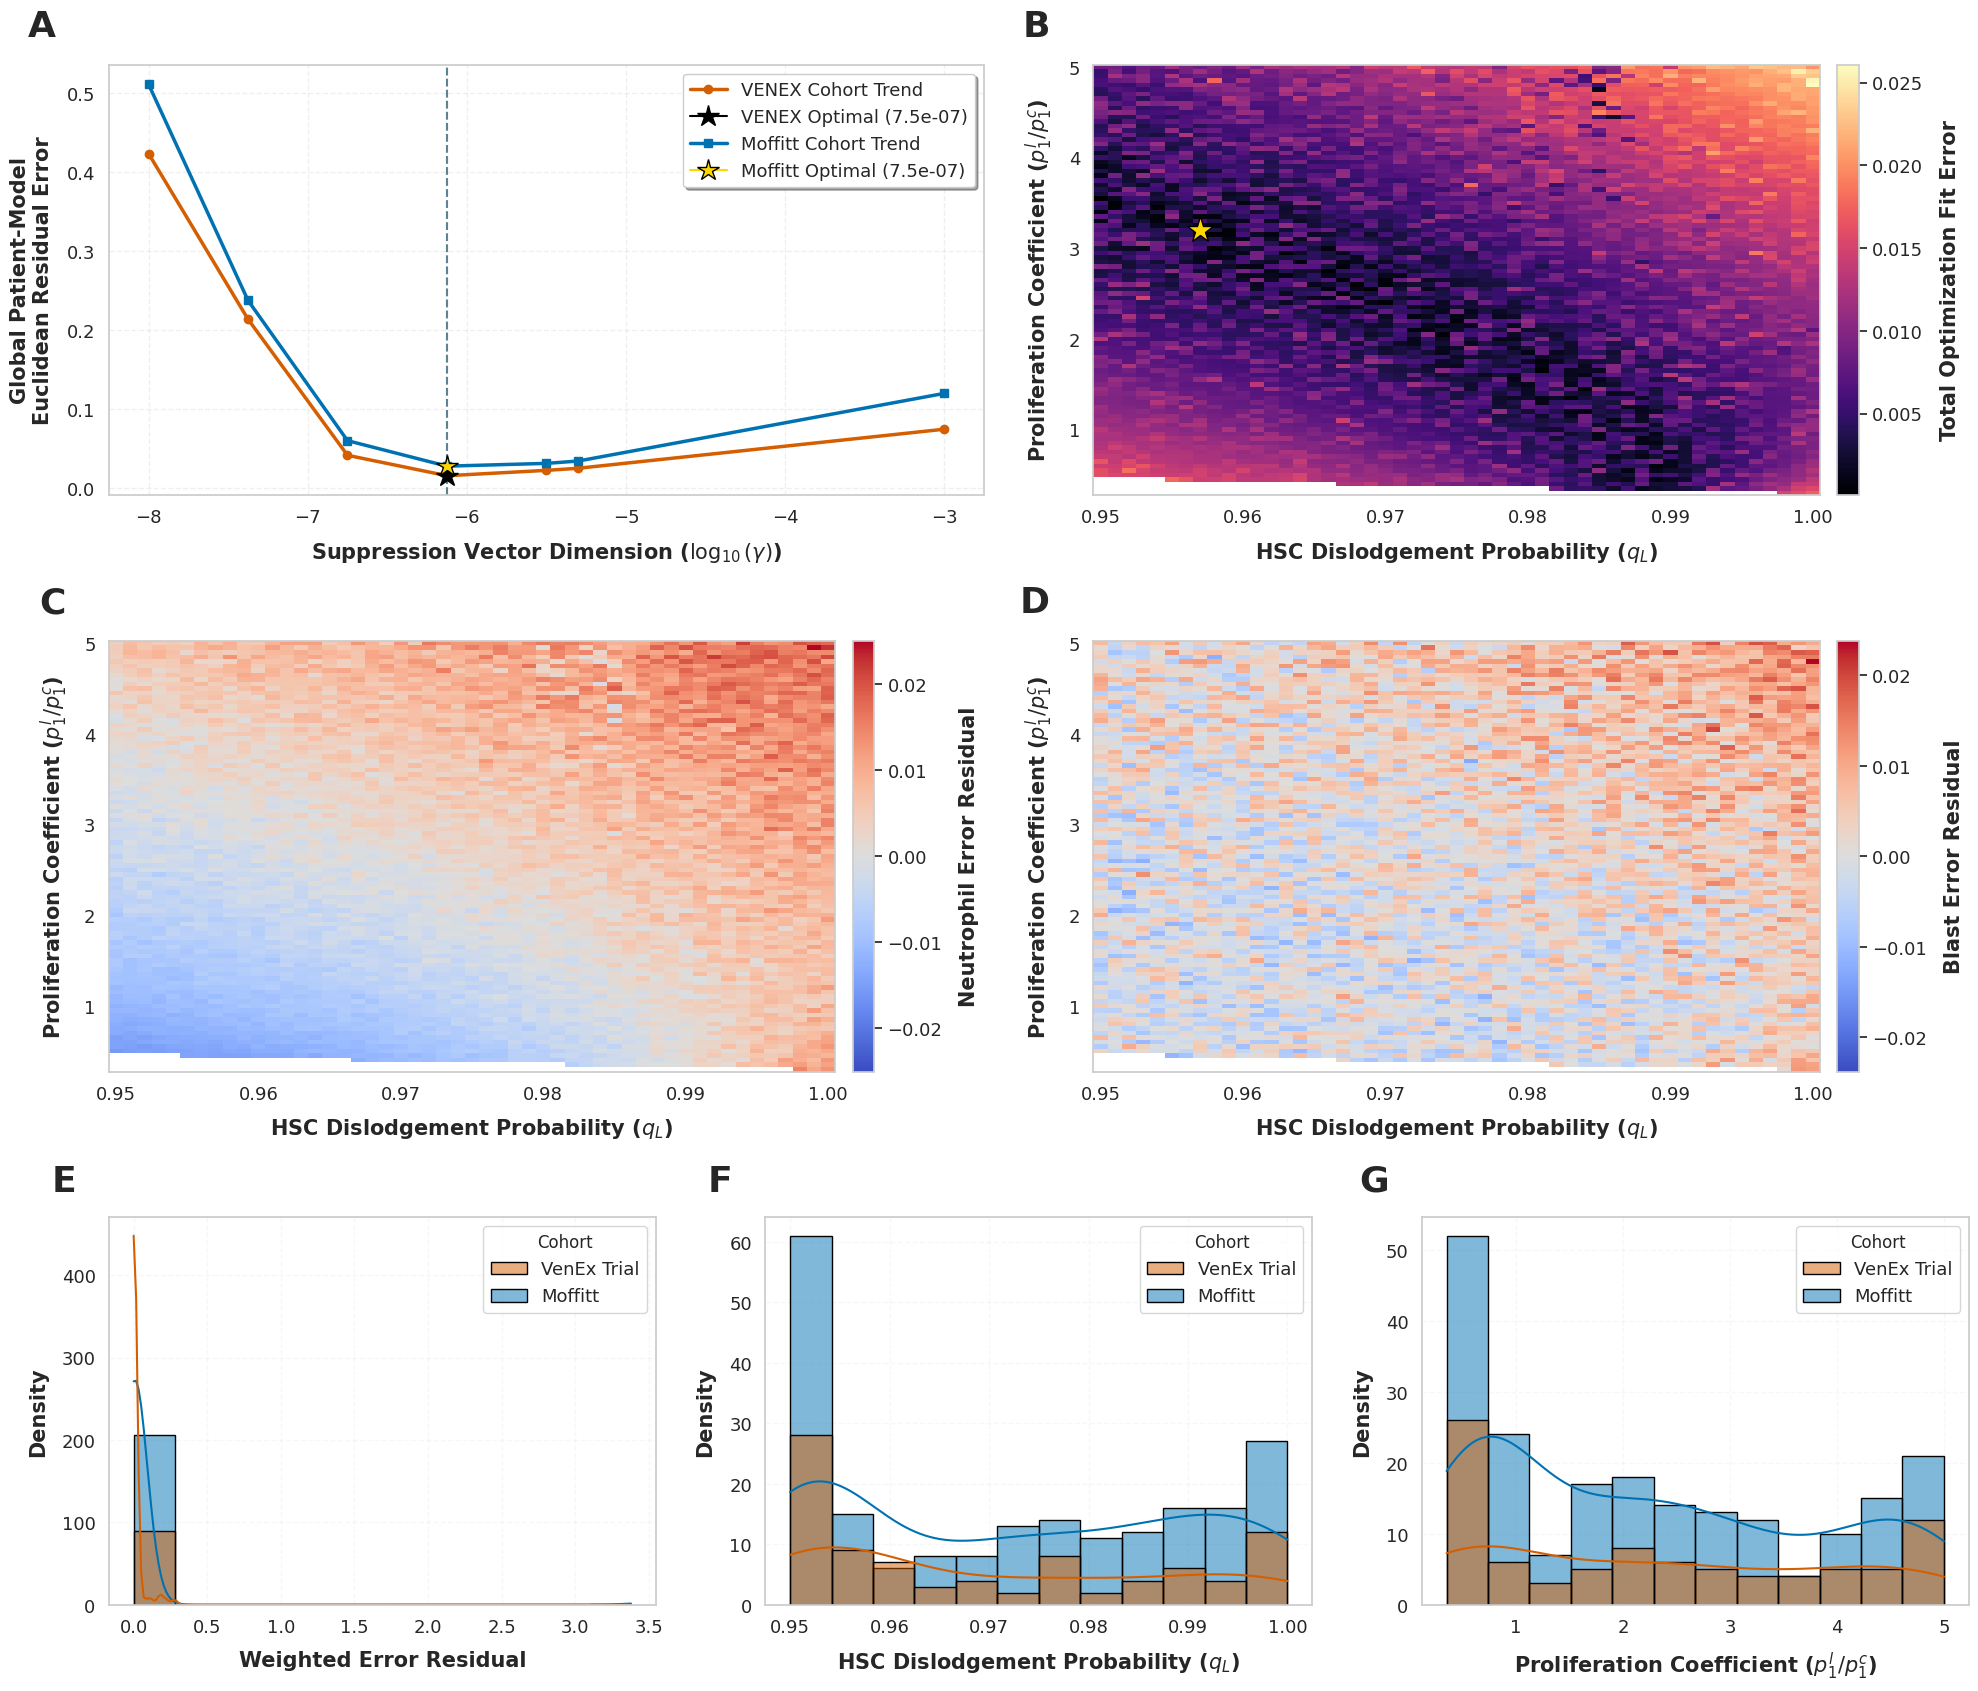

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.colors as mcolors
from matplotlib.colors import CenteredNorm

# =====================================================================
# 1. SETUP, DATA LOADING & STYLING
# =====================================================================
sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

plt.rcParams.update({
    'font.size': 14,
    'axes.labelsize': 15,
    'axes.titlesize': 16,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 13
})

# Okabe-Ito Colorblind-Safe Palette
cohort_colors = {
    'Moffitt': '#0072B2',       # Blue
    'VenEx Trial': '#D55E00'    # Vermilion / Red-Orange
}

# --- File Paths ---
venex_file = "IntermediateResults/venex_gamma_errors.csv"
moffitt_file = "IntermediateResults/moffitt_gamma_errors.csv"
all_errors_file = "IntermediateResults/venex_allerrors.pkl"
moffitt_params_file = "IntermediateResults/moffitt_weighted_params.csv"
venex_params_file = "IntermediateResults/venex_weighted_params.csv"

# --- Data Loading ---
df_all = pd.read_pickle(all_errors_file)
df_all = pd.DataFrame(df_all)

df_all['ID'] = df_all['ID'].astype(str).str.strip()

moffit_params = pd.read_csv(moffitt_params_file)
venex_params = pd.read_csv(venex_params_file)
moffit_params['Cohort'] = "Moffitt"
venex_params['Cohort'] = "VenEx Trial"
patient_weighted_fit = pd.concat([venex_params, moffit_params], ignore_index=True)

# =====================================================================
# 2. FIGURE CANVAS & GRID ARCHITECTURE
# =====================================================================
fig = plt.figure(figsize=(24, 20))
gs = fig.add_gridspec(3, 6, height_ratios=[1, 1, 0.9], hspace=0.35, wspace=0.5)

# Assign Subplots to GridSpec
axA = fig.add_subplot(gs[0, 0:3])  # Panel A: Gamma Search (Left, Row 1)
axB = fig.add_subplot(gs[0, 3:6])  # Panel B: Total Error (Right, Row 1)
axC = fig.add_subplot(gs[1, 0:3])  # Panel C: Neutrophil Error (Left, Row 2)
axD = fig.add_subplot(gs[1, 3:6])  # Panel D: Blast Error (Right, Row 2)
axE = fig.add_subplot(gs[2, 0:2])  # Panel E: SSE Hist (Left, Row 3)
axF = fig.add_subplot(gs[2, 2:4])  # Panel F: q_L Hist (Center, Row 3)
axG = fig.add_subplot(gs[2, 4:6])  # Panel G: Coef Hist (Right, Row 3)

# =====================================================================
# 3. PANEL A: DUAL-COHORT GAMMA SEARCH CURVE
# =====================================================================
if not (os.path.exists(venex_file) and os.path.exists(moffitt_file)):
    axA.text(0.5, 0.5, "Gamma files not found", ha='center', va='center')
else:
    venex_gamma = pd.read_csv(venex_file).sort_values("log_gamma")
    moffitt_gamma = pd.read_csv(moffitt_file).sort_values("log_gamma")

    opt_venex = venex_gamma.loc[venex_gamma["global_error"].idxmin()]
    opt_moffitt = moffitt_gamma.loc[moffitt_gamma["global_error"].idxmin()]

    # VENEX Trend
    axA.plot(venex_gamma["log_gamma"], venex_gamma["global_error"], marker="o", linestyle="-", 
             color=cohort_colors['VenEx Trial'], linewidth=2.5, label="VENEX Cohort Trend")
    axA.axvline(opt_venex["log_gamma"], color=cohort_colors['VenEx Trial'], linestyle="--", alpha=0.6, linewidth=1.5)
    axA.plot(opt_venex["log_gamma"], opt_venex["global_error"], marker="*", color="black", 
             markersize=16, zorder=5, label=f"VENEX Optimal ({opt_venex['gamma_val']:.1e})")

    # Moffitt Trend
    axA.plot(moffitt_gamma["log_gamma"], moffitt_gamma["global_error"], marker="s", linestyle="-", 
             color=cohort_colors['Moffitt'], linewidth=2.5, label="Moffitt Cohort Trend")
    axA.axvline(opt_moffitt["log_gamma"], color=cohort_colors['Moffitt'], linestyle="--", alpha=0.6, linewidth=1.5)
    axA.plot(opt_moffitt["log_gamma"], opt_moffitt["global_error"], marker="*", color="gold", 
             markeredgecolor='black', markersize=16, zorder=5, label=f"Moffitt Optimal ({opt_moffitt['gamma_val']:.1e})")

    axA.set_xlabel(r"Suppression Vector Dimension ($\log_{10}(\gamma)$)", fontweight="bold", labelpad=10)
    axA.set_ylabel("Global Patient-Model\nEuclidean Residual Error", fontweight="bold", labelpad=10)
    axA.legend(loc="upper right", frameon=True, shadow=True)
    axA.grid(True, alpha=0.3, linestyle="--")

# =====================================================================
# 4. PANELS B, C, D:  PARAMETER LANDSCAPES
# =====================================================================
target_patient_id = "9109"

df_grid = df_all[df_all['ID'] == target_patient_id].copy()

if df_grid.empty:
    sample_ids = list(df_all['ID'].unique()[:5])
    raise ValueError(
        f"Patient ID '{target_patient_id}' not found in df_all. "
        f"Available sample IDs in dataset: {sample_ids}"
    )

pivot_neutro = df_grid.pivot_table(index="coef", columns="pHSC", values="err_neutro", aggfunc="mean")
pivot_blast  = df_grid.pivot_table(index="coef", columns="pHSC", values="err_blast", aggfunc="mean")
pivot_total  = df_grid.pivot_table(index="coef", columns="pHSC", values="total_err", aggfunc="mean")

pivot_neutro = pivot_neutro.sort_index().sort_index(axis=1)
pivot_blast  = pivot_blast.sort_index().sort_index(axis=1)
pivot_total  = pivot_total.sort_index().sort_index(axis=1)

# Generate coordinate meshes
X, Y = np.meshgrid(pivot_neutro.columns.values, pivot_neutro.index.values)

# Panel B: Total Optimization Fit Error 
cB = axB.pcolormesh(X, Y, pivot_total.values, cmap="magma", shading="auto")
cbarB = fig.colorbar(cB, ax=axB, pad=0.02)
cbarB.set_label("Total Optimization Fit Error", fontweight="bold", labelpad=12)

# Mark the global minimum on Panel B
min_idx = df_grid["total_err"].idxmin()
best_pHSC = df_grid.loc[min_idx, "pHSC"]
best_coef = df_grid.loc[min_idx, "coef"]
axB.plot(best_pHSC, best_coef, marker="*", color="gold", markeredgecolor="black", markersize=20, zorder=5)

# Panel C: Neutrophil Error Residual (Diverging)
cC = axC.pcolormesh(X, Y, pivot_neutro.values, cmap="coolwarm", shading="auto", norm=CenteredNorm(0))
cbarC = fig.colorbar(cC, ax=axC, pad=0.02)
cbarC.set_label("Neutrophil Error Residual", fontweight="bold", labelpad=12)

# Panel D: Blast Error Residual (Diverging)
cD = axD.pcolormesh(X, Y, pivot_blast.values, cmap="coolwarm", shading="auto", norm=CenteredNorm(0))
cbarD = fig.colorbar(cD, ax=axD, pad=0.02)
cbarD.set_label("Blast Error Residual", fontweight="bold", labelpad=12)

# Format axes labels for B, C, D
for ax in [axB, axC, axD]:
    ax.set_xlabel(r"HSC Dislodgement Probability ($q_L$)", fontweight="bold", labelpad=10)
    ax.set_ylabel(r"Proliferation Coefficient ($p_1^l / p_1^c$)", fontweight="bold", labelpad=10)
    ax.grid(False)

# =====================================================================
# 5. PANELS E, F, G: COHORT PARAMETER DISTRIBUTIONS
# =====================================================================
# Panel E
sns.histplot(data=patient_weighted_fit, x='err_weighted', hue='Cohort', kde=True, 
             ax=axE, edgecolor='black', bins=12, palette=cohort_colors)
axE.set_xlabel('Weighted Error Residual', fontweight='bold', labelpad=10)
axE.set_ylabel('Density', fontweight='bold', labelpad=10)

# Panel F
sns.histplot(data=patient_weighted_fit, x='pHSC_weighted', hue='Cohort', kde=True, 
             ax=axF, edgecolor='black', bins=12, palette=cohort_colors)
axF.set_xlabel(r'HSC Dislodgement Probability ($q_L$)', fontweight='bold', labelpad=10)
axF.set_ylabel('Density', fontweight='bold', labelpad=10) 

# Panel G
sns.histplot(data=patient_weighted_fit, x='coef_weighted', hue='Cohort', kde=True, 
             ax=axG, edgecolor='black', bins=12, palette=cohort_colors)
axG.set_xlabel(r'Proliferation Coefficient ($p_1^l / p_1^c$)', fontweight='bold', labelpad=10)
axG.set_ylabel('Density', fontweight='bold', labelpad=10)

# Legend and grid cleanup for histograms
for ax in [axE, axF, axG]:
    if ax.get_legend():
        sns.move_legend(ax, "upper right", title='Cohort')
    ax.grid(True, alpha=0.15, linestyle='--')

# =====================================================================
# 6.  CORNER STAMPING (A to G)
# =====================================================================
ordered_axes = [axA, axB, axC, axD, axE, axF, axG]
panel_tags = ['A', 'B', 'C', 'D', 'E', 'F', 'G']

for ax, tag in zip(ordered_axes, panel_tags):
    ax.text(-0.06, 1.05, tag, transform=ax.transAxes, 
            fontsize=26, fontweight='bold', va='bottom', ha='right')

# =====================================================================
# 7. SAVE
# =====================================================================
os.makedirs("Figures", exist_ok=True)
plt.tight_layout()
plt.savefig('Figures/Supp_Figure1.png', dpi=300, bbox_inches='tight')
plt.show()